In [1]:
import numpy as np
import matplotlib.pyplot as plt

def H_matrix_phi_space(n_qubits, phi_max, twisted_boundary=True, interaction_strength=0):

    N = 2**n_qubits
    delta_phi = 2 * phi_max / (N - 1)

    def create_phi_space_basis(n_qubits, phi_max):

        phi_basis = np.linspace(-phi_max, phi_max, N, dtype=np.complex128)

        return phi_basis

    K_max = np.pi / delta_phi
    delta_k = 2 * np.pi / (delta_phi * N)

    def create_mom_space_basis(n_qubits, phi_max, twisted_boundary=True):

        if twisted_boundary:
            k_basis = np.linspace(-K_max + delta_k / 2, K_max - delta_k / 2, N, dtype=np.complex128)
        else:
            k_basis = np.linspace(-K_max + delta_k, K_max, N, dtype=np.complex128)

        return k_basis

    def create_exact_mom_matrix_mom_basis(n_qubits, phi_max, twisted_boundary=True):

        if twisted_boundary:
            k_basis = create_mom_space_basis(n_qubits, phi_max)
        else:
            k_basis = create_mom_space_basis(n_qubits, phi_max, twisted_boundary=False)

        exact_mom_operator_mom_basis = np.diag(k_basis**2)

        return exact_mom_operator_mom_basis


    def create_exact_mom_matrix_field_space_basis(n_qubits, phi_max, twisted_boundary=True):

        sqft_matrix = np.zeros((N, N), dtype=np.complex128)

        for x, x_value in enumerate(np.linspace(0, N - 1, N, dtype=np.complex128)):
            for k, k_value in enumerate(np.linspace(-(N-1)/2, (N-1)/2, N, dtype=np.complex128)):
                sqft_matrix[x, k] = np.exp(-2j * np.pi * x_value * k_value / N) / np.sqrt(N)

        if twisted_boundary:
            diagonal_matrix_momentum = create_exact_mom_matrix_mom_basis(n_qubits, phi_max)
        else:
            diagonal_matrix_momentum = create_exact_mom_matrix_mom_basis(n_qubits, phi_max, twisted_boundary=False)

        exact_mom_matrix_field_space = np.dot(sqft_matrix, np.dot(diagonal_matrix_momentum, sqft_matrix.conj().T))

        for i in range(N):
            for j in range(N):
                exact_mom_matrix_field_space[i,j] = exact_mom_matrix_field_space[i,j]

        return exact_mom_matrix_field_space

    phi_basis = create_phi_space_basis(n_qubits, phi_max)
    phi_squared_matrix = np.diag(phi_basis**2)
    phi_4_matrix = np.diag(phi_basis**4)

    exact_mom_matrix_twisted = create_exact_mom_matrix_field_space_basis(n_qubits, phi_max)
    exact_mom_matrix_periodic = create_exact_mom_matrix_field_space_basis(n_qubits, phi_max, twisted_boundary=False)

    H_matrix_t = (phi_squared_matrix + exact_mom_matrix_twisted + 2 * interaction_strength * phi_4_matrix) / 2
    H_matrix_p = (phi_squared_matrix + exact_mom_matrix_periodic+ 2 * interaction_strength * phi_4_matrix) / 2

    if twisted_boundary:
        return H_matrix_t
    else:
        return H_matrix_p


def first_5_eigenenergies(n_qubits, phi_max, twisted_boundary=True):

    if twisted_boundary:
        a = H_matrix_phi_space(n_qubits, phi_max)
    else:
        a = H_matrix_phi_space(n_qubits, phi_max, twisted_boundary=False)

    eigenvalues, eigenvectors = np.linalg.eig(a)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:5]

    return energies


def precisions_for_first_5_energies(n_qubits, phi_max, twisted_boundary=True):

    if twisted_boundary:
        energies = first_5_eigenenergies(n_qubits, phi_max)
    else:
        energies = first_5_eigenenergies(n_qubits, phi_max, twisted_boundary=False)

    actual_energies = np.linspace(0.5, 4.5, 5, dtype=np.complex128)

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    return precisions


def ideal_phi_max(n_qubits):
    N = 2**n_qubits
    phi_max = np.sqrt((np.pi * (N - 1)**2) / (2 * N))
    return phi_max


def first_2_eigenenergies(n_qubits, phi_max, twisted_boundary=True):

    if twisted_boundary:
        a = H_matrix_phi_space(n_qubits, phi_max, interaction_strength=32 / 24)
    else:
        a = H_matrix_phi_space(n_qubits, phi_max, twisted_boundary=False, interaction_strength=32 / 24)

    eigenvalues, eigenvectors = np.linalg.eig(a)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:1]

    return energies


def precisions_for_first_2_energies(n_qubits, phi_max, twisted_boundary=True):

    if twisted_boundary:
        energies = first_2_eigenenergies(n_qubits, phi_max)
    else:
        energies = first_2_eigenenergies(n_qubits, phi_max, twisted_boundary=False)

    actual_energies = [0.85974269044550901935596]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    return precisions


def eigenenergies(n_qubits, alpha):

    omega = (1.4 / alpha)**2 * 2**n_qubits

    N = 2**n_qubits

    def H_basis_eigenenergies(n_qubits, omega):
        return 0.5 * omega * (2 * np.arange(N, dtype=np.float64) + 1)

    def construct_H_basis_matrix(n_qubits, omega):
        basis = H_basis_eigenenergies(n_qubits, omega)
        return np.diag(basis)

    def construct_phi_squared_matrix(n_qubits, omega):

        def A(n):
            return np.sqrt((n+2)*(n+1))
        def B(n):
            return 2*n + 1
        def C(n):
            return np.sqrt(n*(n-1))

        N = 2**n_qubits

        phi_squared_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_squared_matrix[x, y] = B(y)
                elif x == y - 2:
                    phi_squared_matrix[x, y] = C(y)
                elif x == y + 2:
                    phi_squared_matrix[x, y] = A(y)
                else:
                    phi_squared_matrix[x, y] = 0

        return phi_squared_matrix / (2 * omega)

    def construct_delta_H_matrix(n_qubits, omega):

        prefactor = (1 - omega**2) / 2

        phi_squared_matrix = construct_phi_squared_matrix(n_qubits, omega)

        return prefactor * phi_squared_matrix

    def construct_H_int_matrix(n_qubits, omega):

        prefactor = 32 / 24

        def A(n):
            return np.sqrt((n+4)*(n+3)*(n+2)*(n+1))
        def B(n):
            return (4*n + 6)*np.sqrt((n+2)*(n+1))
        def C(n):
            return ((6 * n**2 + 6 * n + 3))
        def D(n):
            return (4*n -2)*np.sqrt((n*(n-1)))
        def E(n):
            return np.sqrt(n*(n-1)*(n-2)*(n-3))

        N = 2**n_qubits

        phi_4_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_4_matrix[x, y] = C(y)
                elif x == y - 4:
                    phi_4_matrix[x, y] = E(y)
                elif x == y - 2:
                    phi_4_matrix[x, y] = D(y)
                elif x == y + 4:
                    phi_4_matrix[x, y] = A(y)
                elif x == y + 2:
                    phi_4_matrix[x, y] = B(y)
                else:
                    phi_4_matrix[x, y] = 0

        return prefactor * phi_4_matrix /( (2 * omega)**2)

    H_basis = construct_H_basis_matrix(n_qubits, omega)

    delta_H = construct_delta_H_matrix(n_qubits, omega)

    H_int = construct_H_int_matrix(n_qubits, omega)

    H = H_basis + delta_H + H_int

    eigenvalues, eigenvectors = np.linalg.eig(H)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:1]

    return energies


def precisions_HO(n_qubits, alpha):

    energies = eigenenergies(n_qubits, alpha)

    actual_energies = [0.85974269044550901935596]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    return precisions




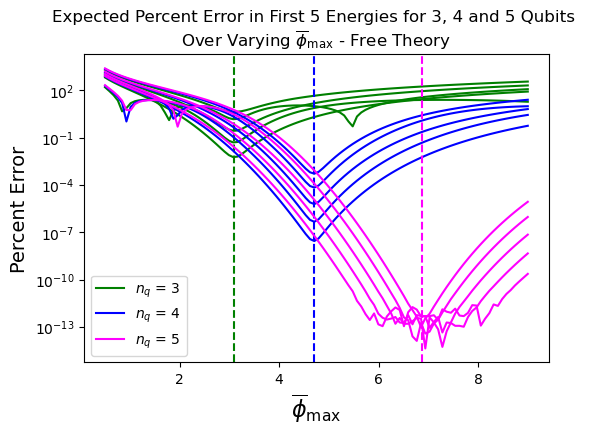

In [4]:

phi_max_values = np.linspace(0.5, 9, 100, dtype=np.complex128)
n_qubits_values = [3, 4, 5]
colors = ["green", "blue", "magenta"]
precisions_array = []
fig, ax = plt.subplots(figsize=(6, 4))
legend_entries = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_for_first_5_energies(n_qubits, phi, twisted_boundary=True) for phi in phi_max_values])
    for j in range(precisions.shape[1]):
        ax.plot(phi_max_values.real, precisions[:, j].real, color=colors[i])

    phi_max_line = ideal_phi_max(n_qubits)
    ax.axvline(phi_max_line, linestyle="--", color=colors[i])

    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], label=r"$n_q$ = {}".format(n_qubits))
        legend_entries.append(n_qubits)

ax.set_yscale("log")
ax.set_xlabel(r"$\overline{\phi}_{\mathrm{max}}$", fontsize=16)
ax.set_ylabel("Percent Error", fontsize=14)
ax.set_title("Expected Percent Error in First 5 Energies for 3, 4 and 5 Qubits \nOver Varying " + r"$\overline{\phi}_{\mathrm{max}}$" + " - Free Theory")
ax.legend()
plt.show()


[0.85974269]


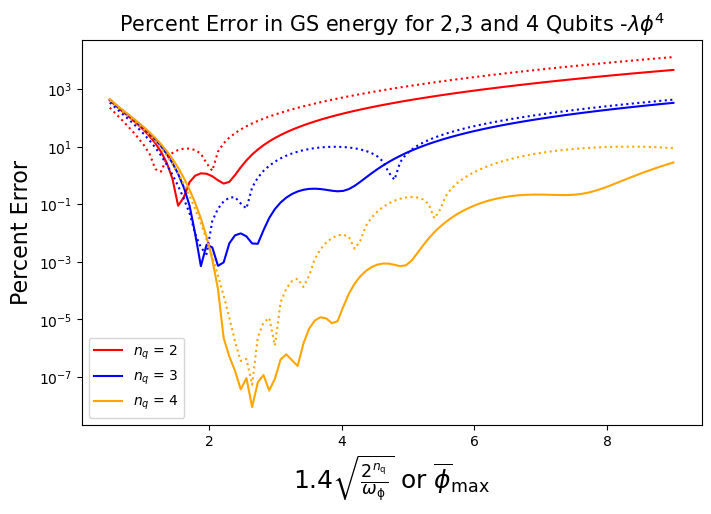

In [3]:


a = eigenenergies(5, 3.45)
print(a)

alpha_values = np.linspace(0.5, 9, 100, dtype=np.float64)
n_qubits_values = [2, 3, 4]
colors = ["red", "blue", "orange", "green"]
HO_precisions_array = []
fig, ax = plt.subplots(figsize=(8, 5))
legend_entries = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO(n_qubits, alpha) for alpha in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i])

    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], label=r"$n_q$ = {}".format(n_qubits))
        legend_entries.append(n_qubits)

JLP_precisions_array = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_for_first_2_energies(n_qubits, phi, twisted_boundary=True) for phi in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i], linestyle="dotted")

    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], linestyle="dotted", label=f"n_qubits = {n_qubits}")
        legend_entries.append(n_qubits)

ax.set_yscale("log")
ax.set_xlabel(r"$1.4\sqrt{\frac{2^{n_{\mathrm{q}}}}{\omega_{\mathrm{\phi}}}}$ or $\overline{\phi}_{\mathrm{max}}$", fontsize=18)
ax.set_ylabel("Percent Error", fontsize=16)
ax.set_title("Percent Error in GS energy for 2,3 and 4 Qubits -" + r"$\lambda\phi^4$", fontsize=15)
ax.legend()
plt.show()
